# CIFAR-10 · Phase 4 findings

Adam (batch 32, learning rate 0.001) led at epoch 10 and peaked at **78.32% validation accuracy** at epoch 19. Larger batches ran faster per epoch but scored lower after 10 epochs.

Run the cell below with Matplotlib installed to rebuild the figure from `phase-4-metrics.csv`.

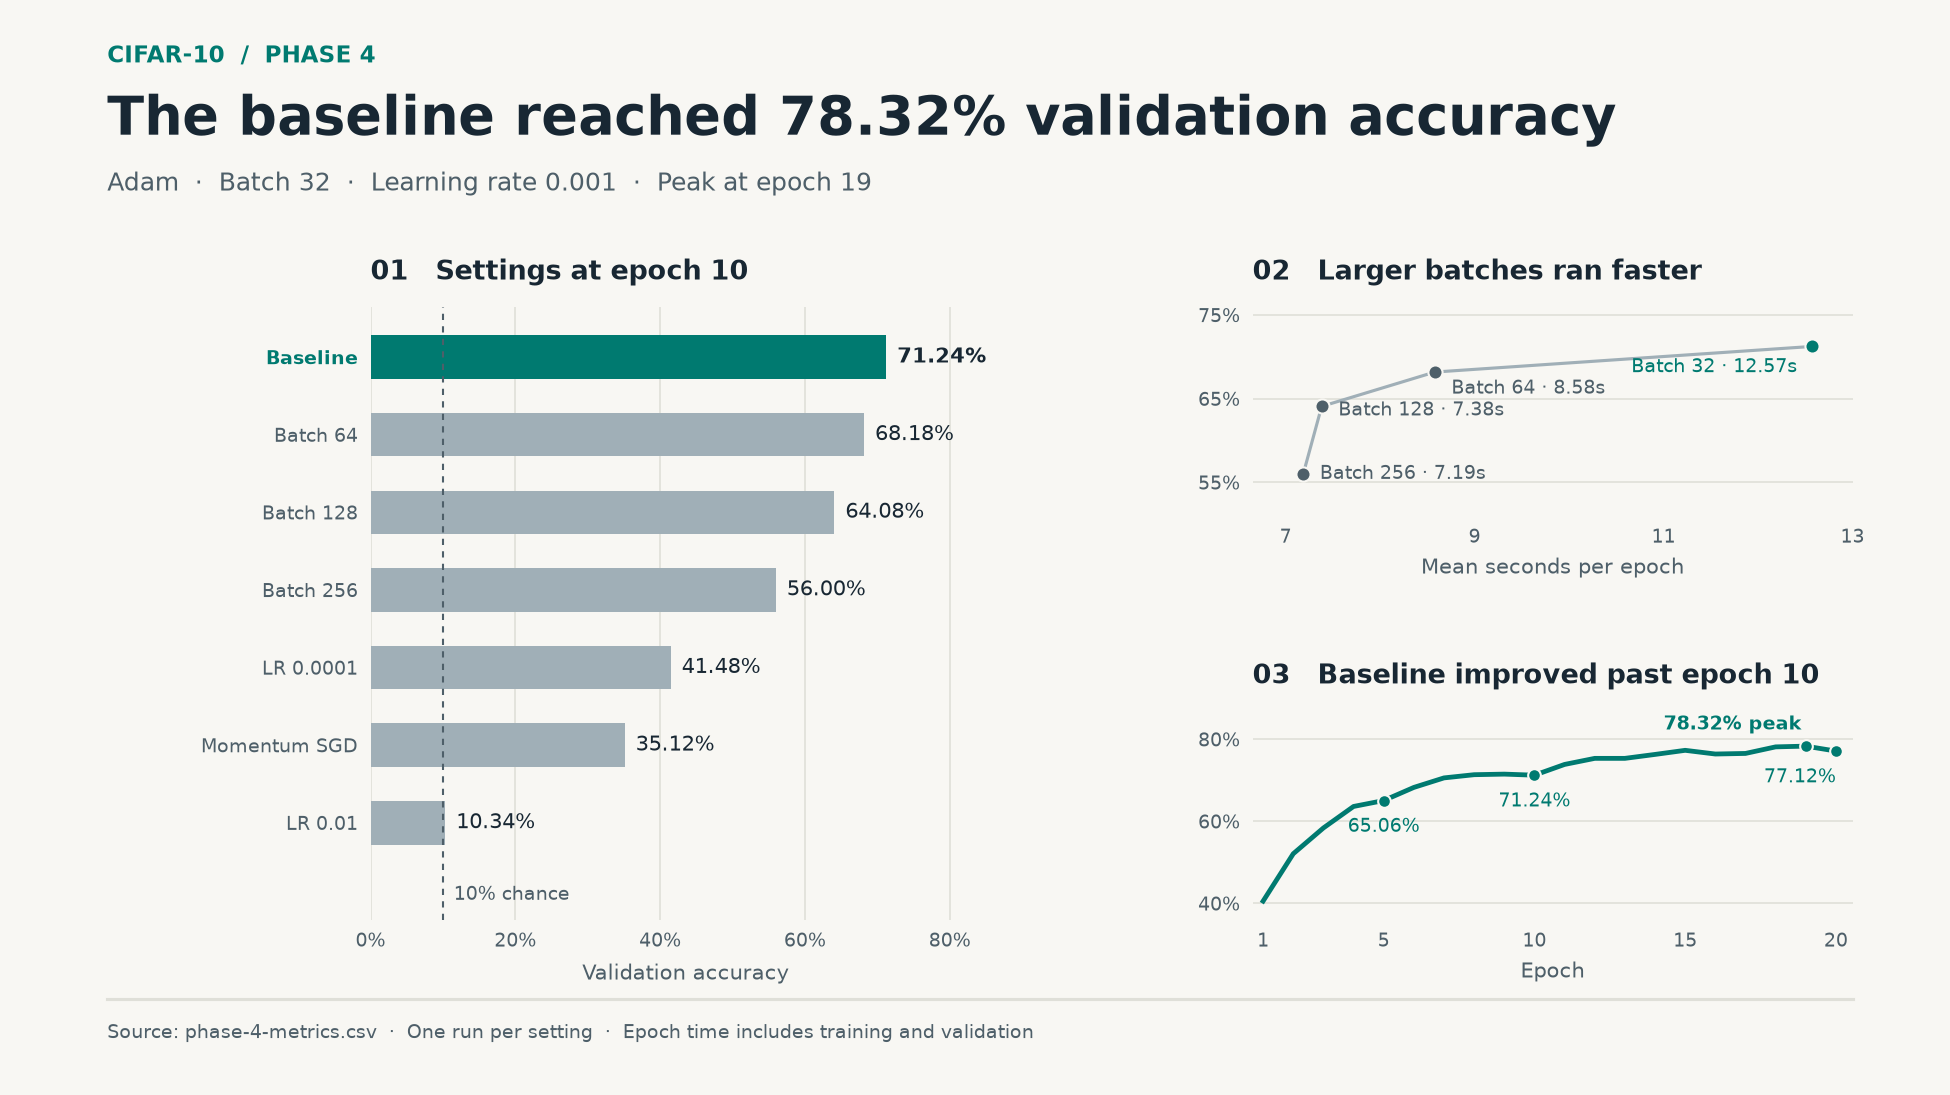

In [1]:
import csv
from collections import defaultdict
from io import BytesIO
from pathlib import Path
from statistics import mean

import matplotlib.pyplot as plt
from IPython.display import Image, display
from matplotlib.ticker import PercentFormatter


PAPER = '#f8f7f3'
INK = '#182733'
MUTED = '#4e5f69'
GRID = '#dfdfd8'
ACCENT = '#007a70'
OTHER = '#a0afb7'


def plot_summary(metrics_path):
    runs = defaultdict(dict)
    with metrics_path.open(newline='', encoding='utf-8') as file:
        for row in csv.DictReader(file):
            runs[row['run']][int(row['epoch'])] = row

    def accuracy(run, epoch):
        return 100 * float(runs[run][epoch]['val_acc'])

    baseline = runs['baseline']
    epochs = sorted(baseline)
    peak = max(epochs, key=lambda epoch: accuracy('baseline', epoch))
    baseline_label = baseline[10]
    fig = plt.figure(figsize=(13, 7.3), facecolor=PAPER)
    layout = fig.add_gridspec(2, 2, left=.19, right=.95, top=.72, bottom=.16,
                              width_ratios=(1.05, 1), wspace=.41, hspace=.93)
    ranking = fig.add_subplot(layout[:, 0])
    speed = fig.add_subplot(layout[0, 1])
    curve = fig.add_subplot(layout[1, 1])

    fig.text(.055, .943, 'CIFAR-10  /  PHASE 4', color=ACCENT, fontsize=11, weight='bold')
    fig.text(.055, .877, f'The baseline reached {accuracy("baseline", peak):.2f}% validation accuracy',
             color=INK, fontsize=26, weight='bold')
    fig.text(.055, .826, f'{baseline_label["optimizer"]}  ·  Batch {baseline_label["batch_size"]}  ·  '
             f'Learning rate {baseline_label["learning_rate"]}  ·  Peak at epoch {peak}',
             color=MUTED, fontsize=12)

    for ax, title in [(ranking, '01   Settings at epoch 10'),
                      (speed, '02   Larger batches ran faster'),
                      (curve, '03   Baseline improved past epoch 10')]:
        ax.set_facecolor(PAPER)
        ax.set_title(title, loc='left', color=INK, fontsize=13, weight='bold', pad=13)
        ax.set_axisbelow(True)
        ax.tick_params(length=0, pad=6, labelsize=9, colors=MUTED)
        ax.spines[:].set_visible(False)

    labels = {
        'baseline': 'Baseline', 'batch-64': 'Batch 64', 'batch-128': 'Batch 128',
        'batch-256': 'Batch 256', 'lr-0.0001': 'LR 0.0001', 'lr-0.01': 'LR 0.01',
        'sgd': 'Momentum SGD',
    }
    ranked = sorted(labels, key=lambda run: accuracy(run, 10), reverse=True)
    for i, run in enumerate(ranked):
        value = accuracy(run, 10)
        color = ACCENT if run == 'baseline' else OTHER
        ranking.barh(i, value, height=.56, color=color)
        ranking.text(value + 1.5, i, f'{value:.2f}%', va='center', fontsize=10,
                     color=INK, weight='bold' if run == 'baseline' else 'normal')
    ranking.set_yticks(range(len(ranked)), [labels[run] for run in ranked])
    ranking.get_yticklabels()[ranked.index('baseline')].set(weight='bold', color=ACCENT)
    ranking.set(xlim=(0, 87), ylim=(7.25, -.65), xticks=[0, 20, 40, 60, 80])
    ranking.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    ranking.grid(axis='x', color=GRID)
    ranking.axvline(10, color=MUTED, linestyle=(0, (3, 3)), linewidth=1)
    ranking.text(11.5, 6.93, '10% chance', color=MUTED, fontsize=9, va='center')
    ranking.set_xlabel('Validation accuracy', color=MUTED, labelpad=6)

    batches = ['batch-256', 'batch-128', 'batch-64', 'baseline']
    times = [mean(float(runs[run][epoch]['seconds']) for epoch in range(1, 11)) for run in batches]
    batch_scores = [accuracy(run, 10) for run in batches]
    speed.plot(times, batch_scores, color=OTHER, linewidth=1.5)
    for run, time, score, offset in zip(batches, times, batch_scores,
                                        [(8, 0), (8, -2), (8, -8), (-7, -10)]):
        color = ACCENT if run == 'baseline' else MUTED
        speed.scatter(time, score, s=46, color=color, edgecolor=PAPER, zorder=3)
        speed.annotate(f'Batch {runs[run][10]["batch_size"]} · {time:.2f}s', (time, score),
                       xytext=offset, textcoords='offset points', va='center',
                       ha='right' if run == 'baseline' else 'left', color=color, fontsize=9)
    speed.set(xlim=(6.65, 13), ylim=(51, 76), xticks=[7, 9, 11, 13], yticks=[55, 65, 75])
    speed.set_xlabel('Mean seconds per epoch', color=MUTED, labelpad=5)

    scores = [accuracy('baseline', epoch) for epoch in epochs]
    curve.plot(epochs, scores, color=ACCENT, linewidth=2.3)
    for epoch in sorted({5, 10, peak, epochs[-1]}):
        curve.scatter(epoch, accuracy('baseline', epoch), s=37, color=ACCENT,
                      edgecolor=PAPER, zorder=3)
    for epoch, offset, align in [(5, (0, -15), 'center'), (10, (0, -15), 'center'),
                                 (peak, (-2, 8), 'right'), (epochs[-1], (0, -15), 'right')]:
        score = accuracy('baseline', epoch)
        curve.annotate(f'{score:.2f}%' + (' peak' if epoch == peak else ''), (epoch, score),
                       xytext=offset, textcoords='offset points', ha=align,
                       color=ACCENT, fontsize=9, weight='bold' if epoch == peak else 'normal')
    curve.set(xlim=(.65, 20.55), ylim=(36, 87), xticks=[1, 5, 10, 15, 20], yticks=[40, 60, 80])
    curve.set_xlabel('Epoch', color=MUTED, labelpad=5)
    for ax in (speed, curve):
        ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
        ax.grid(axis='y', color=GRID)

    fig.add_artist(plt.Line2D([.055, .95], [.088, .088], transform=fig.transFigure, color=GRID))
    fig.text(.055, .052, 'Source: phase-4-metrics.csv  ·  One run per setting  ·  '
             'Epoch time includes training and validation', color=MUTED, fontsize=9)
    output = BytesIO()
    fig.savefig(output, format='png', dpi=150)
    plt.close(fig)
    return Image(data=output.getvalue(), width=1040)


metrics_path = next((folder / 'phase-4-metrics.csv' for folder in (
    Path('.'), Path('result'), Path('cifar-10-from-scratch/result'),
) if (folder / 'phase-4-metrics.csv').is_file()), None)
if metrics_path is None:
    raise FileNotFoundError('Run this notebook from the result folder, project folder, or repo root.')

display(plot_summary(metrics_path))
